In [4]:
import pandas as pd
import numpy as np

In [5]:
nykaa = pd.read_csv("D:\\Priyanka\\3ed project\\marketing-campaign-project\\nykaa_campaign_data_with_nulls.csv")
purplle = pd.read_csv("D:\\Priyanka\\3ed project\\marketing-campaign-project\\purplle_campaign_data_with_nulls.csv")
tira = pd.read_csv("D:\\Priyanka\\3ed project\\marketing-campaign-project\\tira_campaign_data_with_nulls.csv")



In [6]:
print("Nykaa:",nykaa.shape)
print("Purplle:",purplle.shape)
print("Tira:",tira.shape)


Nykaa: (55555, 16)
Purplle: (55555, 16)
Tira: (55555, 16)


In [7]:
nykaa.head(5)

,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025
3,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025
4,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [8]:
nykaa["Brand"] = "Nykaa"
purplle["Brand"]="Purplle"
tira["Brand"]="Tira"

df = pd.concat([nykaa,purplle,tira], ignore_index=True)

print("Combined dataset:",df.shape)
df.head(5)

Combined dataset: (166665, 17)


,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date,Brand
0,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025,Nykaa
1,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025,Nykaa
2,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025,Nykaa
3,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025,Nykaa
4,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024,Nykaa


In [9]:
print("Columns:", df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())


Columns: ['Campaign_ID', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Revenue', 'Acquisition_Cost', 'ROI', 'Language', 'Engagement_Score', 'Customer_Segment', 'Date', 'Brand']

Missing values in each column:
Campaign_ID         5417
Campaign_Type       8358
Target_Audience     8172
Duration            8323
Channel_Used        8282
Impressions         8224
Clicks              8224
Leads               8090
Conversions         8000
Revenue             8304
Acquisition_Cost    8161
ROI                 8298
Language            8299
Engagement_Score    8081
Customer_Segment    8175
Date                8099
Brand                  0
dtype: int64


In [17]:
print("Data type:")
print(df.dtypes)

print("\nRevenue, Acquisition_Cost, ROI summary:")
print(df[["Revenue", "Acquisition_Cost", "ROI"]].describe())

Data type:
Campaign_ID             str
Campaign_Type           str
Target_Audience         str
Duration            float64
Channel_Used            str
Impressions         float64
Clicks              float64
Leads               float64
Conversions         float64
Revenue             float64
Acquisition_Cost    float64
ROI                 float64
Language                str
Engagement_Score    float64
Customer_Segment        str
Date                    str
Brand                   str
dtype: object

Revenue, Acquisition_Cost, ROI summary:
            Revenue  Acquisition_Cost           ROI
count  1.583610e+05     158504.000000  158367.00000
mean   5.138267e+05        376.830560       2.69620
std    4.875933e+05        536.701697       4.48544
min    3.895000e+03          8.180000      -0.99000
25%    1.775800e+05        106.760000       0.05000
50%    3.588720e+05        208.725000       1.24000
75%    6.856400e+05        428.560000       3.58000
max    4.579910e+06      15473.160000     

In [18]:
df_clean = df.copy()


In [19]:
missing_ids = df_clean["Campaign_ID"].isna()
df_clean.loc[missing_ids,"Campaign_ID"] =[f"MISSING_ID_{i}" for i in df_clean.index[missing_ids]]

In [20]:
numeric_cols = df_clean.select_dtypes(include="number").columns


In [21]:
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [22]:
text_cols = df_clean.select_dtypes(include="str").columns.drop(["Campaign_ID","Date"],errors="ignore")
df_clean[text_cols] = df_clean[text_cols].fillna("Unknown")

In [23]:
df_clean = df_clean.drop(columns=["Data"], errors="ignore")

In [24]:
df_clean["Data"]=df_clean["Date"].fillna("Unknown")

print("Missing values per column:")
print(df_clean.isnull().sum())

print("\nTotal missing values:",df_clean.isnull().sum().sum())
print("Cleaned dataset shape:",df_clean.shape)

Missing values per column:


Campaign_ID            0
Campaign_Type          0
Target_Audience        0
Duration               0
Channel_Used           0
Impressions            0
Clicks                 0
Leads                  0
Conversions            0
Revenue                0
Acquisition_Cost       0
ROI                    0
Language               0
Engagement_Score       0
Customer_Segment       0
Date                8099
Brand                  0
Data                   0
dtype: int64

Total missing values: 8099
Cleaned dataset shape: (166665, 18)


In [25]:
df_clean = df_clean.drop(columns=["Data"], errors="ignore")
df_clean["Date"] = df_clean["Date"].fillna("Unknown")

print("Total missing values:", df_clean.isnull().sum().sum())
print("Shape:", df_clean.shape)

Total missing values: 0
Shape: (166665, 17)


In [26]:
df_clean.to_csv("marketing_campaign_cleaned.csv", index=False)
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [28]:
classification_df = df.dropna(subset=["ROI"]).copy()
classification_df["Profit_Flag"] = (
    classification_df["ROI"] > 0
).astype(int)

brand_summary = (
    classification_df
    .groupby("Brand")
    .agg(
        Campaigns=("Campaign_ID","count"),
        Avg_Revenue=("Revenue", "mean"),
        Avg_ROI=("ROI","mean"),
        Profit_Rate=("Profit_Flag","mean")
    )
    .round(2)
)

brand_summary["Profit_Rate"] = (brand_summary["Profit_Rate"] * 100).round(2)

brand_summary

,Campaigns,Avg_Revenue,Avg_ROI,Profit_Rate
Brand,,,,
Nykaa,52730,516508.29,2.72,76.0
Purplle,50275,513608.80,2.68,76.0
Tira,50218,513400.77,2.69,76.0


In [29]:
brand_summary = (
    classification_df
    .groupby("Brand")
    .agg(
        Campaigns=("Profit_Flag","size"),
        Avg_Revenue=("Revenue","mean"),
        Avg_ROI=("ROI","mean"),
        Profit_Rate=("Profit_Flag","mean")
    )
    .round(2)
)

brand_summary["Profit_Rate"] =(
    brand_summary["Profit_Rate"] * 100
).round(2)

brand_summary

,Campaigns,Avg_Revenue,Avg_ROI,Profit_Rate
Brand,,,,
Nykaa,52730,516508.29,2.72,76.0
Purplle,52824,513608.80,2.68,76.0
Tira,52813,513400.77,2.69,76.0


In [31]:
channel_df = classification_df.copy()

channel_df["Channel_Used"] = (
    channel_df["Channel_Used"]
    .fillna("Unknown")
    .str.split(",")
)

channel_df = channel_df.explode("Channel_Used")
channel_df["Channel_Used"] = channel_df["Channel_Used"].str.strip()

channel_summary = (
    channel_df
    .groupby("Channel_Used")
    .agg(
        Campaigns=("Profit_Flag","size"),
        Avg_Revenue=("Revenue","mean"),
        Avg_ROI=("ROI","mean"),
        Profit_Rate=("Profit_Flag","mean")
    )
    .round(2)
)

channel_summary["Profit_Rate"] = (
    channel_summary["Profit_Rate"] * 100
).round(2)

channel_summary.sort_values("Avg_ROI", ascending=False)

,Campaigns,Avg_Revenue,Avg_ROI,Profit_Rate
Channel_Used,,,,
Email,50289,518265.80,2.74,76.0
Instagram,50295,518482.20,2.74,76.0
Facebook,50138,514928.12,2.69,76.0
Google,50159,513771.31,2.69,76.0
WhatsApp,50094,513939.14,2.69,76.0
YouTube,50166,512139.12,2.67,76.0
Unknown,7893,507844.94,2.64,75.0


Matplotlib is building the font cache; this may take a moment.


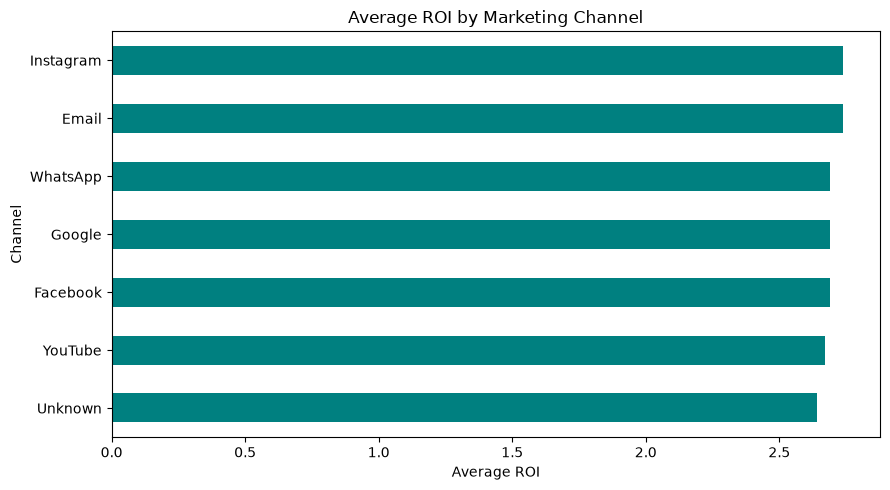

In [32]:
import matplotlib.pyplot as plt

channel_summary["Avg_ROI"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="teal"
)

plt.title("Average ROI by Marketing Channel")
plt.xlabel("Average ROI")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
regression_df = df.dropna(subset=["Revenue"]).copy()


In [35]:
y = regression_df["Revenue"]

In [ ]:
# modal input columns
x = regression_df.drop(columns=["Revenue","ROI","Campaign_ID","Date"])


In [37]:
# 80% training, 20% testing
x_train, x_test, y_train, y_test = train_test_split(
    x,y,test_size=0.2, random_state=42
)



In [38]:
print("Training rows:", x_train.shape[0])
print("Testing rows:", x_test.shape[0])
print("Input columns:", x_train.columns.tolist())

Training rows: 126688
Testing rows: 31673
Input columns: ['Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Impressions', 'Clicks', 'Leads', 'Conversions', 'Acquisition_Cost', 'Language', 'Engagement_Score', 'Customer_Segment', 'Brand']


In [41]:
from sklearn.preprocessing import MultiLabelBinarizer

def split_channels(series):
    return series.fillna("Unknown").astype(str).apply(
        lambda value:[channel.strip() for channel in value.split(",")
                      if channel.strip()]
    )

train_channels = split_channels(x_train["Channel_Used"])
test_channels = split_channels(x_test["Channel_Used"])

channel_encoder = MultiLabelBinarizer()

train_channel_values = channel_encoder.fit_transform(train_channels)
test_channel_values = channel_encoder.transform(test_channels)

channel_columns = [
    f"Channel_{name}" for name in channel_encoder.classes_
]

train_channel_df = pd.DataFrame(
    train_channel_values,
    columns=channel_columns,
    index=x_train.index
)

test_channel_df = pd.DataFrame(
    test_channel_values,
    columns=channel_columns,
    index=x_test.index
)

x_train_model = pd.concat(
    [x_train.drop(columns=["Channel_Used"]), train_channel_df],
    axis=1
)

x_test_model = pd.concat(
    [x_test.drop(columns=["Channel_Used"]),test_channel_df],
    axis=1
)


print("Training input shape:", x_train_model.shape)
print("Testing input shape:", x_test_model.shape)
print("Encoded channels:", channel_encoder.classes_.tolist())

Training input shape: (126688, 19)
Testing input shape: (31673, 19)
Encoded channels: ['Email', 'Facebook', 'Google', 'Instagram', 'Unknown', 'WhatsApp', 'YouTube']


In [ ]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Numeric  category columns 
numeric_features = x_train_model.select_dtypes(include="number").columns.tolist()
categorical_features = [
    col for col in x_train_model.columns
    if col not in numeric_features
]

# Numeric value missing - median
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Text values--value--
# - category-- columns--
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# - preprocessing--
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

# Linear Regression pipeline
revenue_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

revenue_model.fit(x_train_model, y_train)
revenue_predictions = revenue_model.predict(x_test_model)

print("MAE:", mean_absolute_error(y_test, revenue_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, revenue_predictions)))
print("R2:", r2_score(y_test, revenue_predictions))

MAE: 163516.12479941422
RMSE: 249166.8941556945
R2: 0.7430198667084724


In [48]:
from sklearn.ensemble import RandomForestRegressor

rf_revenue_model = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_revenue_model.fit(x_train_model,y_train)
rf_predictions = rf_revenue_model.predict(x_test_model)

print("Random Forest MAE:", mean_absolute_error(y_test, rf_predictions))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("Random Forest R2:", r2_score(y_test, rf_predictions))



Random Forest MAE: 157418.71319098413
Random Forest RMSE: 238555.25509605385
Random Forest R2: 0.7644425477170794


In [ ]:
from sklearn.model_selection import train_test_split

#  ROI - rows 
classification_df = df.dropna(subset=["ROI"]).copy()

# ROI > 0 - Profit (1),  Loss (0)
classification_df["Profit_Flag"] = (
    classification_df["ROI"] > 0
).astype(int)

# ROI- Campaign_ID/Date- input-
x_class = classification_df.drop(
    columns=["Profit_Flag", "ROI", "Campaign_ID", "Date"]
)
y_class = classification_df["Profit_Flag"]

x_train_cls, x_test_cls, y_train_cls, y_test_cls = train_test_split(
    x_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training rows:", x_train_cls.shape[0])
print("Testing rows:", x_test_cls.shape[0])
print("Profit/Loss distribution in training data:")
print(y_train_cls.value_counts(normalize=True) * 100)

Training rows: 126693
Testing rows: 31674
Profit/Loss distribution in training data:
Profit_Flag
1    76.073658
0    23.926342
Name: proportion, dtype: float64


In [53]:
from sklearn.preprocessing import MultiLabelBinarizer

def split_channels(series):
    return series.fillna("Unknown").astype(str).apply(
        lambda value: [channel.strip() for channel in value.split(",")
                       if channel.strip()]
    )

train_channels_cls = split_channels(x_train_cls["Channel_Used"])
test_channels_cls = split_channels(x_test_cls["Channel_Used"])

channel_encoder_cls = MultiLabelBinarizer()

train_channel_values_cls = channel_encoder_cls.fit_transform(train_channels_cls)
test_channel_values_cls = channel_encoder_cls.transform(test_channels_cls)

channel_columns_cls = [
    f"Channel_{name}" for name in channel_encoder_cls.classes_
]

train_channel_df_cls = pd.DataFrame(
    train_channel_values_cls,
    columns=channel_columns_cls,
    index=x_train_cls.index
)

test_channel_df_cls = pd.DataFrame(
    test_channel_values_cls,
    columns=channel_columns_cls,
    index=x_test_cls.index
)

x_train_cls_model = pd.concat(
    [x_train_cls.drop(columns=["Channel_Used"]), train_channel_df_cls],
    axis=1
)

x_test_cls_model = pd.concat(
    [x_test_cls.drop(columns=["Channel_Used"]), test_channel_df_cls],
    axis=1
)

print("Training input shape:", x_train_cls_model.shape)
print("Testing input shape:", x_test_cls_model.shape)
print("Encoded channels:", channel_encoder_cls.classes_.tolist())


Training input shape: (126693, 20)
Testing input shape: (31674, 20)
Encoded channels: ['Email', 'Facebook', 'Google', 'Instagram', 'Unknown', 'WhatsApp', 'YouTube']


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

# Numeric/category columns -
numeric_features_cls = x_train_cls_model.select_dtypes(
    include="number"
).columns.tolist()

categorical_features_cls = [
    col for col in x_train_cls_model.columns
    if col not in numeric_features_cls
]

# Numeric values - scale -
numeric_preprocessor_cls = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Text values -one-hot encode -
categorical_preprocessor_cls = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_cls = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor_cls, numeric_features_cls),
    ("categorical", categorical_preprocessor_cls, categorical_features_cls)
])

# Logistic Regression model
profit_model = Pipeline(steps=[
    ("preprocessor", preprocessor_cls),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

profit_model.fit(x_train_cls_model, y_train_cls)
profit_predictions = profit_model.predict(x_test_cls_model)

print("Accuracy:", accuracy_score(y_test_cls, profit_predictions))
print("Precision:", precision_score(y_test_cls, profit_predictions, zero_division=0))
print("Recall:", recall_score(y_test_cls, profit_predictions, zero_division=0))
print("F1-score:", f1_score(y_test_cls, profit_predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test_cls, profit_predictions))

Accuracy: 0.9224600618804066
Precision: 0.9782531824611033
Recall: 0.9184926958831341
F1-score: 0.9474315068493151
Confusion matrix:
[[ 7086   492]
 [ 1964 22132]]


In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_profit_model = Pipeline(steps=[
    ("preprocessor", preprocessor_cls),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_profit_model.fit(x_train_cls_model, y_train_cls)
rf_profit_predictions = rf_profit_model.predict(x_test_cls_model)

print("Random Forest Accuracy:",
      accuracy_score(y_test_cls, rf_profit_predictions))
print("Random Forest Precision:",
      precision_score(y_test_cls, rf_profit_predictions, zero_division=0))
print("Random Forest Recall:",
      recall_score(y_test_cls, rf_profit_predictions, zero_division=0))
print("Random Forest F1-score:",
      f1_score(y_test_cls, rf_profit_predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test_cls, rf_profit_predictions))


Random Forest Accuracy: 0.9575361495232683
Random Forest Precision: 0.9877374265746259
Random Forest Recall: 0.956050796812749
Random Forest F1-score: 0.9716358421729686
Confusion matrix:
[[ 7292   286]
 [ 1059 23037]]


In [56]:
model_comparison = pd.DataFrame([
    {
        "Task": "Revenue",
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test, revenue_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, revenue_predictions)),
        "R2_or_Accuracy": r2_score(y_test, revenue_predictions)
    },
    {
        "Task": "Revenue",
        "Model": "Random Forest Regressor",
        "MAE": mean_absolute_error(y_test, rf_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, rf_predictions)),
        "R2_or_Accuracy": r2_score(y_test, rf_predictions)
    },
    {
        "Task": "Profit/Loss",
        "Model": "Logistic Regression",
        "MAE": np.nan,
        "RMSE": np.nan,
        "R2_or_Accuracy": accuracy_score(y_test_cls, profit_predictions)
    },
    {
        "Task": "Profit/Loss",
        "Model": "Random Forest Classifier",
        "MAE": np.nan,
        "RMSE": np.nan,
        "R2_or_Accuracy": accuracy_score(y_test_cls, rf_profit_predictions)
    }
])

model_comparison.round(3)

,Task,Model,MAE,RMSE,R2_or_Accuracy
0,Revenue,Linear Regression,163516.125,249166.894,0.743
1,Revenue,Random Forest Regressor,157418.713,238555.255,0.764
2,Profit/Loss,Logistic Regression,NaN,NaN,0.922
3,Profit/Loss,Random Forest Classifier,NaN,NaN,0.958


In [57]:
model_comparison.to_csv("model_comparison.csv", index=False)
print("Model comparison saved.")

Model comparison saved.


In [58]:
import joblib

joblib.dump(
    {
        "revenue_model": rf_revenue_model,
        "profit_model": rf_profit_model,
        "revenue_channel_encoder": channel_encoder,
        "profit_channel_encoder": channel_encoder_cls
    },
    "marketing_models.joblib"
)

print("Models and encoders saved.")

Models and encoders saved.
